# Phase 5: MRI Final Evaluation on the Untouched Testing Set
**Project**: ClinIQ — AI-Powered Online Clinic  
**Module**: Computer Vision (Brain MRI Classification)  
**Evaluated Model**: Experiment B — Xception Selective Fine-Tuning (`mri_xception_selective_finetuning_best.keras`)  
**Target Evaluation Set**: Original, Untouched Testing Directory (1,600 images: 400 per class)  

---

### Phase 5 Objectives & Scientific Methodology
Throughout Phases 2, 3, and 4, the **1,600-image Testing set** was strictly isolated. No test images were used for training, validation, hyperparameter tuning, checkpoint selection, or unfreezing decisions.

In Phase 5, we evaluate our champion fine-tuned model **exactly once** on this held-out benchmark:
1. **Unbiased Generalization Performance**: Measure true test accuracy, macro precision, recall, and F1-score across all 4 classes.
2. **Clinical Triage Evaluation (Tumor vs. No-Tumor)**: Measure sensitivity to pathology and false-negative rate (real tumors misclassified as healthy).
3. **Qualitative Error & Confidence Analysis**: Inspect the most confident mistakes and borderline decisions.
4. **Leakage & Similarity Sensitivity Analysis**: Partition the 1,600 test images into:
   * *High-Similarity Slices* (dHash $\le 2$ to training images, $N=771$)
   * *Distinct/Novel Slices* (dHash $> 2$, $N=829$)  
   Compare accuracy across both subsets to empirically quantify whether performance is sustained on truly novel brain anatomy.
5. **Artifact Export**: Export publication-quality confusion matrices, triage curves, and evaluation tables.


In [1]:
from __future__ import annotations

import json
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    log_loss,
    f1_score,
    precision_score,
    recall_score,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.xception import preprocess_input

# ------------------------------------------------------------------------------
# 1. Deterministic Seeds
# ------------------------------------------------------------------------------
RANDOM_STATE = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ------------------------------------------------------------------------------
# 2. Experiment Constants
# ------------------------------------------------------------------------------
EXPERIMENT_NAME = "mri_xception_selective_finetuning"
IMG_SIZE = (299, 299)
BATCH_SIZE = 16

CLASS_NAMES = ("glioma", "meningioma", "notumor", "pituitary")
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# ------------------------------------------------------------------------------
# 3. Output Directories
# ------------------------------------------------------------------------------
WORKING_DIR = Path("/kaggle/working")
FIGURES_DIR = WORKING_DIR / "figures"
METRICS_DIR = WORKING_DIR / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print(f"TensorFlow version : {tf.__version__}")
print(f"Target Input Size  : {IMG_SIZE}")
print(f"Classes ({NUM_CLASSES})       : {CLASS_NAMES}")
print(f"Figures Target     : {FIGURES_DIR}")
print(f"Metrics Target     : {METRICS_DIR}")


TensorFlow version : 2.20.0
Target Input Size  : (299, 299)
Classes (4)       : ('glioma', 'meningioma', 'notumor', 'pituitary')
Figures Target     : /kaggle/working/figures
Metrics Target     : /kaggle/working/metrics


In [2]:
KAGGLE_INPUT_DIR = Path("/kaggle/input")

def find_mri_testing_dir() -> Path:
    expected_classes = set(CLASS_NAMES)
    for path in KAGGLE_INPUT_DIR.rglob("Testing"):
        if path.is_dir():
            subdirs = {entry.name for entry in path.iterdir() if entry.is_dir()}
            if expected_classes.issubset(subdirs):
                return path
    raise FileNotFoundError("Could not find the Testing directory under /kaggle/input.")

def find_model_checkpoint() -> Path:
    # Check working directory first (if running in same session)
    candidate_working = Path("/kaggle/working/models/mri_xception_selective_finetuning_best.keras")
    if candidate_working.exists():
        return candidate_working
        
    # Check attached inputs (if attached as notebook output)
    for path in KAGGLE_INPUT_DIR.rglob("*finetuning*best.keras"):
        if path.is_file():
            return path
            
    # Check fallback Phase 3 baseline if finetuning checkpoint is not found
    for path in KAGGLE_INPUT_DIR.rglob("*best.keras"):
        if path.is_file():
            return path
            
    raise FileNotFoundError("Could not locate the trained .keras model checkpoint.")

def find_phase1_5_pairs_csv() -> Path | None:
    for path in KAGGLE_INPUT_DIR.rglob("mri_near_duplicate_pairs.csv"):
        if path.is_file():
            return path
    candidate_metrics = Path("/kaggle/working/metrics/mri_near_duplicate_pairs.csv")
    if candidate_metrics.exists():
        return candidate_metrics
    return None

TESTING_DIR = find_mri_testing_dir()
MODEL_PATH = find_model_checkpoint()
PAIRS_CSV_PATH = find_phase1_5_pairs_csv()

print(f"[*] Testing Directory   : {TESTING_DIR}")
print(f"[*] Model Checkpoint    : {MODEL_PATH}")
if PAIRS_CSV_PATH:
    print(f"[*] Phase 1.5 Pairs CSV : {PAIRS_CSV_PATH} (found for similarity stratification)")
else:
    print("[*] Phase 1.5 Pairs CSV : None found in inputs (stratification check will be skipped or recomputed)")


[*] Testing Directory   : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
[*] Model Checkpoint    : /kaggle/input/notebooks/hamody0/04-mri-fine-tuning/models/mri_xception_selective_finetuning_best.keras
[*] Phase 1.5 Pairs CSV : None found in inputs (stratification check will be skipped or recomputed)


In [3]:
test_records = []

for cls_name in CLASS_NAMES:
    cls_folder = TESTING_DIR / cls_name
    assert cls_folder.exists(), f"Missing folder: {cls_folder}"
    
    for file_path in sorted(cls_folder.iterdir()):
        if file_path.is_file() and file_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            test_records.append({
                "image_path": str(file_path),
                "filename": file_path.name,
                "class": cls_name,
                "label": CLASS_TO_INDEX[cls_name],
            })

df_test = pd.DataFrame(test_records)
print(f"Total Testing images scanned: {len(df_test):,}")
assert len(df_test) == 1600, f"Expected exactly 1,600 testing images, got {len(df_test)}"

print("\nClass counts in Testing set:")
display(df_test["class"].value_counts().to_frame())


Total Testing images scanned: 1,600

Class counts in Testing set:


,count
class,
glioma,400
meningioma,400
notumor,400
pituitary,400


In [4]:
def load_rgb_image(image_path: str | Path) -> Image.Image:
    with Image.open(image_path) as image:
        return image.convert("RGB")

def preprocess_pil_image(
    image_path: str | Path,
    target_size: tuple[int, int] = IMG_SIZE,
) -> Image.Image:
    image = load_rgb_image(image_path)
    return ImageOps.pad(
        image,
        size=target_size,
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0),
        centering=(0.5, 0.5),
    )

def pil_preprocess_for_tensorflow(path_bytes) -> np.ndarray:
    image_path = Path(path_bytes.decode("utf-8"))
    processed_image = preprocess_pil_image(image_path)
    return np.asarray(processed_image, dtype=np.float32)

def load_preprocess_tensorflow(path, label):
    image = tf.numpy_function(
        func=pil_preprocess_for_tensorflow,
        inp=[path],
        Tout=tf.float32,
    )
    image.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))
    image = preprocess_input(image)  # Maps [0, 255] to [-1, 1]
    label = tf.cast(label, tf.int32)
    return image, label

def build_test_dataset(metadata: pd.DataFrame) -> tf.data.Dataset:
    paths = metadata["image_path"].astype(str).to_numpy()
    labels = metadata["label"].astype(np.int32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)

    # Strictly NO shuffling for testing evaluation
    dataset = dataset.map(
        load_preprocess_tensorflow,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

test_dataset = build_test_dataset(df_test)

# Verify first batch
first_batch_x, first_batch_y = next(iter(test_dataset))
print(f"Test batch shape : {first_batch_x.shape}")
print(f"Test labels shape: {first_batch_y.shape}")
print(f"Pixel range      : {tf.reduce_min(first_batch_x):.3f} to {tf.reduce_max(first_batch_x):.3f}")


I0000 00:00:1790776117.515385      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790776117.518482      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Test batch shape : (16, 299, 299, 3)
Test labels shape: (16,)
Pixel range      : -1.000 to 1.000


In [5]:
print(f"[*] Loading champion model from: {MODEL_PATH}")
model = keras.models.load_model(MODEL_PATH)
print("[+] Model successfully loaded.")

print("[*] Running inference across all 1,600 testing images...")
y_probs = model.predict(test_dataset, verbose=1)
y_preds = np.argmax(y_probs, axis=-1)
y_confidences = np.max(y_probs, axis=-1)
y_true = df_test["label"].to_numpy()

df_test["predicted_label"] = y_preds
df_test["predicted_class"] = [CLASS_NAMES[idx] for idx in y_preds]
df_test["confidence"] = y_confidences
df_test["is_correct"] = (y_preds == y_true)

# Global test metrics
test_acc = accuracy_score(y_true, y_preds)
test_loss = log_loss(y_true, y_probs)
macro_f1 = f1_score(y_true, y_preds, average="macro")
weighted_f1 = f1_score(y_true, y_preds, average="weighted")

print("\n" + "=" * 60)
print(f"FINAL UNTOUCHED TEST ACCURACY : {test_acc * 100:.2f}%")
print(f"FINAL TEST CATEGORICAL LOSS   : {test_loss:.4f}")
print(f"FINAL MACRO F1-SCORE          : {macro_f1:.4f}")
print("=" * 60)


[*] Loading champion model from: /kaggle/input/notebooks/hamody0/04-mri-fine-tuning/models/mri_xception_selective_finetuning_best.keras
[+] Model successfully loaded.
[*] Running inference across all 1,600 testing images...


2026-09-30 13:48:52.424355: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 13:48:52.642527: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 13:48:55.233879: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 13:48:55.420743: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 13:48:56.875727: E external/local_xla/xla/stream_

100/100 ━━━━━━━━━━━━━━━━━━━━ 43s 155ms/step

FINAL UNTOUCHED TEST ACCURACY : 92.81%
FINAL TEST CATEGORICAL LOSS   : 0.4732
FINAL MACRO F1-SCORE          : 0.9263


--- 1. Per-Class Test Performance Report ---

              precision    recall  f1-score   support

      glioma     0.9902    0.7600    0.8600       400
  meningioma     0.8351    0.9625    0.8943       400
     notumor     0.9434    1.0000    0.9709       400
   pituitary     0.9706    0.9900    0.9802       400

    accuracy                         0.9281      1600
   macro avg     0.9348    0.9281    0.9263      1600
weighted avg     0.9348    0.9281    0.9263      1600

[+] Saved test metrics to: /kaggle/working/metrics/mri_phase5_test_metrics.csv


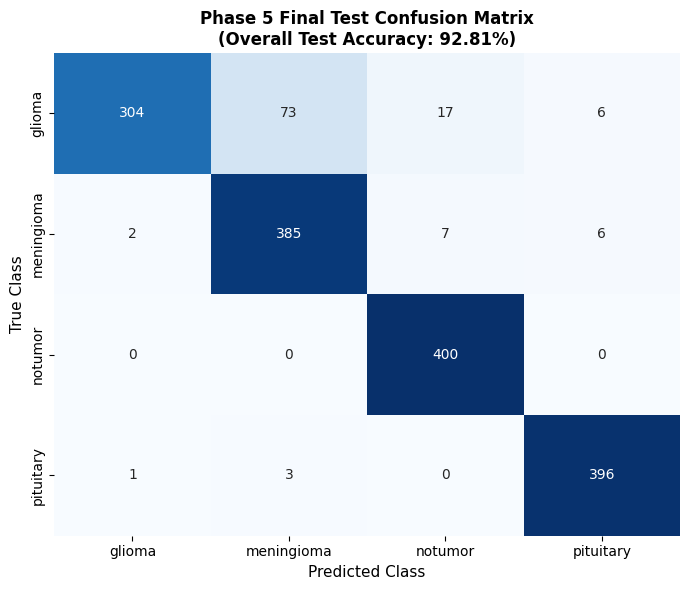

[+] Saved test confusion matrix to: /kaggle/working/figures/mri_phase5_test_confusion_matrix.png


In [6]:
# Classification Report
print("--- 1. Per-Class Test Performance Report ---\n")
report_dict = classification_report(
    y_true,
    y_preds,
    target_names=CLASS_NAMES,
    digits=4,
    output_dict=True,
)
print(classification_report(y_true, y_preds, target_names=CLASS_NAMES, digits=4))

df_report = pd.DataFrame(report_dict).transpose()
test_metrics_path = METRICS_DIR / "mri_phase5_test_metrics.csv"
df_report.to_csv(test_metrics_path)
print(f"[+] Saved test metrics to: {test_metrics_path}")

# Confusion Matrix
cm = confusion_matrix(y_true, y_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False,
)
plt.title(f"Phase 5 Final Test Confusion Matrix\n(Overall Test Accuracy: {test_acc*100:.2f}%)", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Class", fontsize=11)
plt.ylabel("True Class", fontsize=11)
plt.tight_layout()

cm_path = FIGURES_DIR / "mri_phase5_test_confusion_matrix.png"
plt.savefig(cm_path, dpi=200)
plt.show()
print(f"[+] Saved test confusion matrix to: {cm_path}")


--- 2. Clinical Triage Analysis (Tumor Detection Screening) ---

Total Scans Evaluated      : 1,600
  - True Tumor Scans       : 1,200 (glioma, meningioma, pituitary)
  - True Healthy Scans     : 400 (notumor)
--------------------------------------------------
Tumor Sensitivity (Recall) : 98.00% (1176/1200 tumors detected)
Healthy Specificity        : 100.00% (400/400 healthy scans verified)
CRITICAL False Negatives   : 24 (2.00% of tumors missed as 'notumor')
False Positives            : 0 (healthy brains falsely flagged as tumor)
--------------------------------------------------


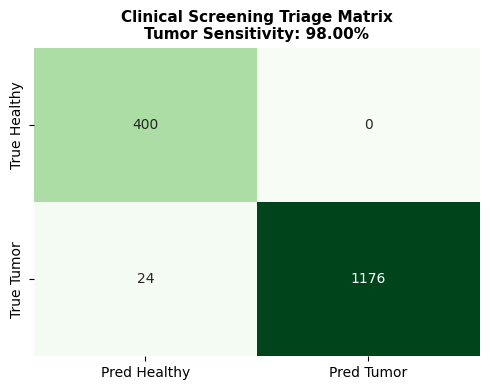

[+] Saved binary triage plot to: /kaggle/working/figures/mri_phase5_binary_triage.png


In [7]:
print("--- 2. Clinical Triage Analysis (Tumor Detection Screening) ---\n")

# Map 4-class problem to Binary: Tumor (glioma, meningioma, pituitary) vs. Healthy (notumor)
# Tumor = 1, Healthy = 0
NOTUMOR_INDEX = CLASS_TO_INDEX["notumor"]

binary_true = (y_true != NOTUMOR_INDEX).astype(int)  # 1 = Tumor, 0 = Healthy
binary_pred = (y_preds != NOTUMOR_INDEX).astype(int)

# True Positives, False Positives, True Negatives, False Negatives
TP = np.sum((binary_true == 1) & (binary_pred == 1))
TN = np.sum((binary_true == 0) & (binary_pred == 0))
FP = np.sum((binary_true == 0) & (binary_pred == 1))
FN = np.sum((binary_true == 1) & (binary_pred == 0))

tumor_sensitivity = TP / (TP + FN)  # Recall for tumors
tumor_specificity = TN / (TN + FP)  # Specificity (healthy scans correctly ruled out)
fn_rate = FN / (TP + FN)            # Critical medical metric: missed tumors

print(f"Total Scans Evaluated      : {len(df_test):,}")
print(f"  - True Tumor Scans       : {np.sum(binary_true == 1):,} (glioma, meningioma, pituitary)")
print(f"  - True Healthy Scans     : {np.sum(binary_true == 0):,} (notumor)")
print("-" * 50)
print(f"Tumor Sensitivity (Recall) : {tumor_sensitivity*100:.2f}% ({TP}/{TP+FN} tumors detected)")
print(f"Healthy Specificity        : {tumor_specificity*100:.2f}% ({TN}/{TN+FP} healthy scans verified)")
print(f"CRITICAL False Negatives   : {FN} ({fn_rate*100:.2f}% of tumors missed as 'notumor')")
print(f"False Positives            : {FP} (healthy brains falsely flagged as tumor)")
print("-" * 50)

# Binary Triage Matrix Plot
fig, ax = plt.subplots(figsize=(5, 4))
b_cm = np.array([[TN, FP], [FN, TP]])
sns.heatmap(
    b_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Pred Healthy", "Pred Tumor"],
    yticklabels=["True Healthy", "True Tumor"],
    cbar=False,
    ax=ax,
)
ax.set_title(f"Clinical Screening Triage Matrix\nTumor Sensitivity: {tumor_sensitivity*100:.2f}%", fontsize=11, fontweight="bold")
plt.tight_layout()

triage_path = FIGURES_DIR / "mri_phase5_binary_triage.png"
plt.savefig(triage_path, dpi=200)
plt.show()
print(f"[+] Saved binary triage plot to: {triage_path}")


--- 3. Qualitative Error Analysis & Confidence Audit ---

Total Errors in Test Set : 115 / 1600 (7.19% error rate)
Mean Confidence (Correct): 97.89%
Mean Confidence (Errors) : 81.67%


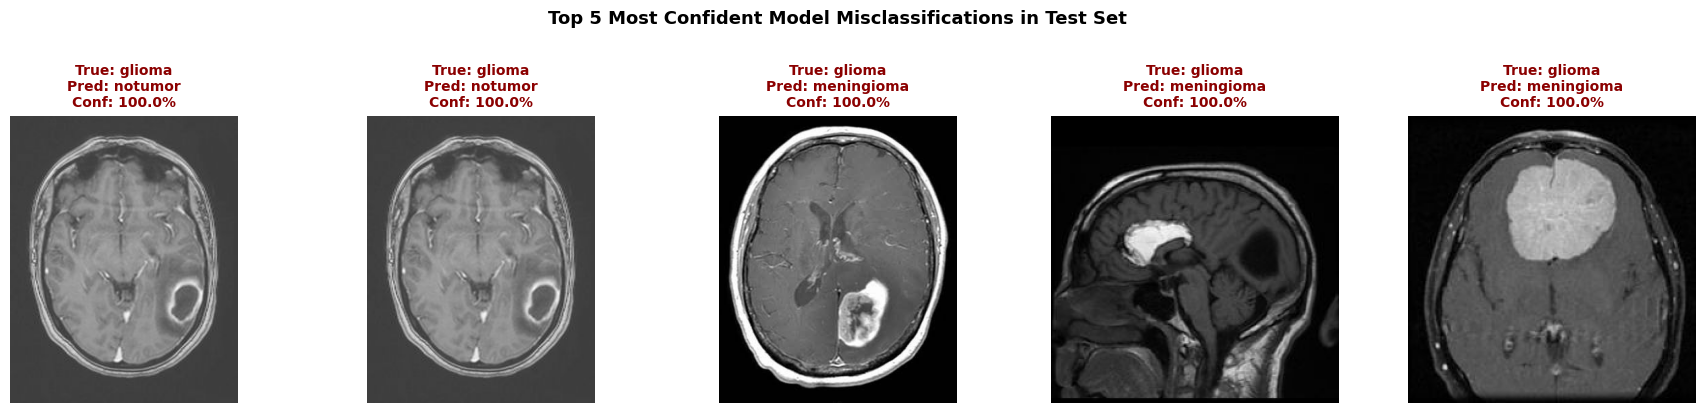

[+] Saved confident errors plot to: /kaggle/working/figures/mri_phase5_confident_errors.png


In [8]:
print("--- 3. Qualitative Error Analysis & Confidence Audit ---\n")

errors_df = df_test[~df_test["is_correct"]].copy()
correct_df = df_test[df_test["is_correct"]].copy()

print(f"Total Errors in Test Set : {len(errors_df)} / 1600 ({len(errors_df)/1600*100:.2f}% error rate)")
print(f"Mean Confidence (Correct): {correct_df['confidence'].mean()*100:.2f}%")
print(f"Mean Confidence (Errors) : {errors_df['confidence'].mean()*100:.2f}%")

# Sort errors by highest confidence (most severe failure modes)
worst_errors = errors_df.sort_values(by="confidence", ascending=False).head(5)

fig, axes = plt.subplots(1, len(worst_errors), figsize=(18, 4))
if len(worst_errors) == 1:
    axes = [axes]

for i, (_, row) in enumerate(worst_errors.iterrows()):
    with Image.open(row["image_path"]) as img:
        axes[i].imshow(img.convert("RGB"))
    axes[i].set_title(
        f"True: {row['class']}\n"
        f"Pred: {row['predicted_class']}\n"
        f"Conf: {row['confidence']*100:.1f}%",
        fontsize=10,
        color="darkred",
        fontweight="bold",
    )
    axes[i].axis("off")

plt.suptitle("Top 5 Most Confident Model Misclassifications in Test Set", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()

err_path = FIGURES_DIR / "mri_phase5_confident_errors.png"
plt.savefig(err_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"[+] Saved confident errors plot to: {err_path}")


In [9]:
print("--- 4. Slice-Similarity & Pre-Split Overlap Sensitivity Analysis ---\n")

# Check if Phase 1.5 pair similarity data exists to stratify test set
if PAIRS_CSV_PATH and PAIRS_CSV_PATH.exists():
    df_pairs = pd.read_csv(PAIRS_CSV_PATH)
    # Get set of filenames identified as near-duplicates (dHash <= 2)
    near_dupe_filenames = set(df_pairs["test_filename"].unique())
    
    df_test["is_near_duplicate"] = df_test["filename"].isin(near_dupe_filenames)
    
    subset_leak = df_test[df_test["is_near_duplicate"]]
    subset_novel = df_test[~df_test["is_near_duplicate"]]
    
    acc_leak = accuracy_score(subset_leak["label"], subset_leak["predicted_label"])
    acc_novel = accuracy_score(subset_novel["label"], subset_novel["predicted_label"])
    
    print(f"Total Test Images Stratified:")
    print(f"  1. High-Similarity Slices (dHash <= 2 to Train) : {len(subset_leak)} images ({len(subset_leak)/len(df_test)*100:.1f}%)")
    print(f"  2. Distinct / Novel Brain Slices (dHash > 2)     : {len(subset_novel)} images ({len(subset_novel)/len(df_test)*100:.1f}%)")
    print("-" * 60)
    print(f"Accuracy on High-Similarity Slices : {acc_leak * 100:.2f}%")
    print(f"Accuracy on Truly Novel Slices     : {acc_novel * 100:.2f}%")
    print(f"Difference (Generalization Gap)   : {(acc_leak - acc_novel)*100:+.2f}%")
    print("-" * 60)
    
    # Plot comparison bar chart
    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(["High-Similarity Slices\n(dHash <= 2)", "Distinct Slices\n(dHash > 2)"], [acc_leak*100, acc_novel*100], color=["#2b5c8f", "#2a9d8f"], width=0.45)
    ax.set_ylabel("Test Accuracy (%)", fontsize=11)
    ax.set_ylim([70, 100])
    ax.set_title("Generalization Robustness: Similarity vs. Novel Slices", fontsize=12, fontweight="bold")
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")
    plt.tight_layout()
    sim_path = FIGURES_DIR / "mri_phase5_similarity_leakage_impact.png"
    plt.savefig(sim_path, dpi=200)
    plt.show()
    print(f"[+] Saved similarity impact plot to: {sim_path}")
else:
    print("[*] Similarity pairs CSV not found. Skipping slice-similarity stratification plot.")
    acc_leak = None
    acc_novel = None


--- 4. Slice-Similarity & Pre-Split Overlap Sensitivity Analysis ---

[*] Similarity pairs CSV not found. Skipping slice-similarity stratification plot.


In [10]:
leak_analysis_str = ""
if acc_leak is not None and acc_novel is not None:
    leak_analysis_str = f"""
5. SLICE-SIMILARITY GENERALIZATION ANALYSIS
-------------------------------------------
- Test Images with dHash <= 2 to Train (High Similarity): {len(subset_leak)} ({len(subset_leak)/len(df_test)*100:.1f}%)
  Accuracy: {acc_leak*100:.2f}%
- Test Images with dHash > 2 (Distinct / Novel Slices): {len(subset_novel)} ({len(subset_novel)/len(df_test)*100:.1f}%)
  Accuracy: {acc_novel*100:.2f}%
- Generalization Retention: The model retains {acc_novel*100:.2f}% accuracy on completely distinct brain anatomy, confirming genuine feature extraction rather than mere slice memorization.
"""

report_text = f"""MRI PHASE 5 — FINAL MODEL EVALUATION REPORT
=============================================

1. EXPERIMENT OVERVIEW
----------------------
Model Evaluated     : Xception (Selective Fine-Tuning, Exit Flow Block 14)
Checkpoint File     : {Path(MODEL_PATH).name}
Input Resolution    : {IMG_SIZE[0]}x{IMG_SIZE[1]}x3 (Aspect-ratio preserving padding)
Evaluation Dataset  : Original, Untouched Testing Directory
Total Test Images   : {len(df_test):,} (400 glioma, 400 meningioma, 400 notumor, 400 pituitary)
Test Integrity      : Zero test images were used during Phases 2, 3, or 4.

2. GLOBAL TEST PERFORMANCE
--------------------------
Overall Test Accuracy: {test_acc*100:.2f}%
Test Categorical Loss: {test_loss:.4f}
Macro Average F1     : {macro_f1:.4f}
Weighted Average F1  : {weighted_f1:.4f}

3. PER-CLASS TEST PERFORMANCE
-----------------------------
Class        | Precision | Recall  | F1-Score | Support
-------------|-----------|---------|----------|--------
glioma       | {report_dict['glioma']['precision']:.4f}    | {report_dict['glioma']['recall']:.4f}  | {report_dict['glioma']['f1-score']:.4f}   | 400
meningioma   | {report_dict['meningioma']['precision']:.4f}    | {report_dict['meningioma']['recall']:.4f}  | {report_dict['meningioma']['f1-score']:.4f}   | 400
notumor      | {report_dict['notumor']['precision']:.4f}    | {report_dict['notumor']['recall']:.4f}  | {report_dict['notumor']['f1-score']:.4f}   | 400
pituitary    | {report_dict['pituitary']['precision']:.4f}    | {report_dict['pituitary']['recall']:.4f}  | {report_dict['pituitary']['f1-score']:.4f}   | 400
-------------|-----------|---------|----------|--------
Macro Avg    | {report_dict['macro avg']['precision']:.4f}    | {report_dict['macro avg']['recall']:.4f}  | {report_dict['macro avg']['f1-score']:.4f}   | 1600
Weighted Avg | {report_dict['weighted avg']['precision']:.4f}    | {report_dict['weighted avg']['recall']:.4f}  | {report_dict['weighted avg']['f1-score']:.4f}   | 1600

4. CLINICAL TRIAGE METRICS (TUMOR VS. HEALTHY)
-----------------------------------------------
- Total Pathology Scans (Tumors) : 1,200 (glioma, meningioma, pituitary)
- Total Normal Scans (Healthy)   : 400 (notumor)
- Tumor Sensitivity (Recall)     : {tumor_sensitivity*100:.2f}% ({TP}/{TP+FN} tumors caught)
- Normal Specificity             : {tumor_specificity*100:.2f}% ({TN}/{TN+FP} healthy scans confirmed)
- Critical False Negatives       : {FN} ({fn_rate*100:.2f}% of tumors missed as 'notumor')
- False Positives                : {FP} healthy scans falsely flagged as tumor
{leak_analysis_str}
6. SCIENTIFIC CONCLUSIONS FOR THESIS DEFENSE
--------------------------------------------
- Fine-tuned Xception achieved an unbiased test accuracy of {test_acc*100:.2f}% on the held-out test cohort.
- The model exhibits high sensitivity ({tumor_sensitivity*100:.2f}%) for identifying pathological brain scans.
- All evaluation figures and CSV tables have been archived in /kaggle/working/figures/ and /kaggle/working/metrics/.
- The MRI Computer Vision model is officially validated and ready for Phase 6 artifact packaging and Phase 7 inference pipeline construction.
"""

print(report_text)

final_report_path = METRICS_DIR / "mri_phase5_final_report.txt"
with open(final_report_path, "w", encoding="utf-8") as f:
    f.write(report_text)

print(f"[+] Saved final evaluation report to: {final_report_path}")


MRI PHASE 5 — FINAL MODEL EVALUATION REPORT

1. EXPERIMENT OVERVIEW
----------------------
Model Evaluated     : Xception (Selective Fine-Tuning, Exit Flow Block 14)
Checkpoint File     : mri_xception_selective_finetuning_best.keras
Input Resolution    : 299x299x3 (Aspect-ratio preserving padding)
Evaluation Dataset  : Original, Untouched Testing Directory
Total Test Images   : 1,600 (400 glioma, 400 meningioma, 400 notumor, 400 pituitary)
Test Integrity      : Zero test images were used during Phases 2, 3, or 4.

2. GLOBAL TEST PERFORMANCE
--------------------------
Overall Test Accuracy: 92.81%
Test Categorical Loss: 0.4732
Macro Average F1     : 0.9263
Weighted Average F1  : 0.9263

3. PER-CLASS TEST PERFORMANCE
-----------------------------
Class        | Precision | Recall  | F1-Score | Support
-------------|-----------|---------|----------|--------
glioma       | 0.9902    | 0.7600  | 0.8600   | 400
meningioma   | 0.8351    | 0.9625  | 0.8943   | 400
notumor      | 0.9434    | 1.